In [1]:
import sys
from pathlib import Path

import pandas as pd


current_directory = Path.cwd().resolve()

project_root = (
    current_directory.parent
    if current_directory.name == "notebooks"
    else current_directory
)

if not (project_root / "rate_my_recipe").is_dir():
    raise FileNotFoundError(
        "Run Jupyter from the repository root or notebooks directory"
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from rate_my_recipe.ranking import RecipeRanker

recipe_rating_summary = pd.read_csv(
    project_root / "data/processed/recipe_rating_summary.csv"
)

recipe_ranker = RecipeRanker(recipe_rating_summary)

global_mean_rating = recipe_ranker.calculate_global_mean_rating()

naive_ranking = recipe_ranker.rank_by_mean_rating()

bayesian_ranking = recipe_ranker.rank_by_bayesian_score(
    smoothing_strength=10
)

print(f"Global mean rating: {global_mean_rating:.4f}")

display(naive_ranking.head(10))
display(bayesian_ranking.head(10))


Global mean rating: 4.6615


,rank,recipe_id,recipe_name,preparation_time_minutes,ingredient_count,interaction_count,valid_rating_count,mean_valid_rating,ranking_score
0,1,486496,bacon lattice tomato muffins rsc,60,11,202,192,5.0,5.0
1,2,474520,company s coming mashed potatoes,40,12,97,95,5.0,5.0
2,3,515167,simply irresistible tropical potato salad sp5,13,5,74,73,5.0,5.0
3,4,154351,kittencal s balsamic vinaigrette,120,7,71,69,5.0,5.0
4,5,186029,the best creole cajun seasoning mix,5,10,68,67,5.0,5.0
5,6,495275,peppered buffalo ranch shrimp pizza rsc,30,13,70,64,5.0,5.0
6,7,55309,caprese salad tomatoes italian marinated toma...,10,6,52,52,5.0,5.0
7,8,524863,ragu shuka ragu,40,12,50,49,5.0,5.0
8,9,495124,warm roasted root vegetable and chicken salad ...,50,9,47,46,5.0,5.0
9,10,514605,animal style skillet potatoes sp5,35,5,53,46,5.0,5.0


,rank,recipe_id,recipe_name,preparation_time_minutes,ingredient_count,interaction_count,valid_rating_count,mean_valid_rating,ranking_score
0,1,486496,bacon lattice tomato muffins rsc,60,11,202,192,5.000000,4.983243
1,2,486261,mexican stack up rsc,75,22,217,217,4.990783,4.976277
2,3,474520,company s coming mashed potatoes,40,12,97,95,5.000000,4.967762
3,4,515167,simply irresistible tropical potato salad sp5,13,5,74,73,5.000000,4.959217
4,5,154351,kittencal s balsamic vinaigrette,120,7,71,69,5.000000,4.957152
5,6,186029,the best creole cajun seasoning mix,5,10,68,67,5.000000,4.956039
6,7,46262,uncle bill s method for cooking turkey,330,6,184,175,4.971429,4.954676
7,8,495275,peppered buffalo ranch shrimp pizza rsc,30,13,70,64,5.000000,4.954257
8,9,77497,2 handed kitchen sink tomato sandwich,15,4,85,81,4.987654,4.951813
9,10,74805,never weep whipped cream,5,4,80,78,4.987179,4.950170


# Ranking Evaluation

We compare the naive and Bayesian-style rankings using
top-k overlap, changes in ranking positions, rating-count
distributions, and sensitivity to the smoothing parameter.

These analyses evaluate ranking behavior rather than
proving which method produces better recommendations.

In [2]:
from rate_my_recipe.evaluation import RankingEvaluator

ranking_evaluator = RankingEvaluator(
    naive_ranking=naive_ranking,
    bayesian_ranking=bayesian_ranking,
)

top_k_comparisons = pd.DataFrame([
    ranking_evaluator.compare_top_k(top_k)
    for top_k in [10, 20, 50, 100]
])

top_20_rating_counts = (
    ranking_evaluator.compare_top_k_rating_counts(top_k=20)
)

rank_changes = ranking_evaluator.compare_rank_changes()

smoothing_sensitivity = (
    ranking_evaluator.evaluate_smoothing_sensitivity(
        recipe_ranker=recipe_ranker,
        smoothing_strengths=[1, 5, 10, 20, 50, 100],
        top_k=20,
    )
)

display(top_k_comparisons)
display(top_20_rating_counts)
display(rank_changes.head(20))
display(smoothing_sensitivity)


,top_k,shared_recipe_count,overlap_percentage
0,10,6,60.0
1,20,10,50.0
2,50,29,58.0
3,100,46,46.0


,ranking_method,mean_rating_count,median_rating_count,min_rating_count,max_rating_count
0,naive,57.7,45.0,38,192
1,bayesian,121.6,79.5,46,587


,recipe_id,naive_rank,naive_score,bayesian_rank,bayesian_score,valid_rating_count,rank_improvement
0,106627,119755,4.832685,3469,4.826273,257,116286
1,150863,119863,4.825633,3626,4.823223,671,116237
2,36984,119756,4.832298,3654,4.822310,161,116102
3,2886,120040,4.819415,4442,4.818296,1401,115598
4,24672,123874,4.799065,8346,4.792924,214,115528
5,67256,123926,4.793132,8459,4.792039,1194,115467
6,200296,119883,4.823961,4416,4.820083,409,115467
7,129345,119811,4.827160,4365,4.820613,243,115446
8,13546,123875,4.798995,8451,4.792416,199,115424
9,57130,119882,4.824034,4478,4.817346,233,115404


,smoothing_strength,overlap_with_naive_percentage,median_top_k_rating_count
0,1,100.0,45.0
1,5,75.0,65.5
2,10,50.0,79.5
3,20,30.0,100.5
4,50,10.0,192.5
5,100,5.0,287.0


In [3]:
rank_changes_with_names = rank_changes.merge(
    recipe_rating_summary[["recipe_id", "recipe_name"]],
    on="recipe_id",
    validate="one_to_one",
)

most_improved_recipes = rank_changes_with_names.nlargest(
    10,
    "rank_improvement",
)

most_declined_recipes = rank_changes_with_names.nsmallest(
    10,
    "rank_improvement",
)

display(most_improved_recipes)
display(most_declined_recipes)


,recipe_id,naive_rank,naive_score,bayesian_rank,bayesian_score,valid_rating_count,rank_improvement,recipe_name
0,106627,119755,4.832685,3469,4.826273,257,116286,caramelized butternut squash
1,150863,119863,4.825633,3626,4.823223,671,116237,panera s cream cheese potato soup
2,36984,119756,4.832298,3654,4.822310,161,116102,the best browned beef stew ever
3,2886,120040,4.819415,4442,4.818296,1401,115598,best banana bread
4,24672,123874,4.799065,8346,4.792924,214,115528,the ultimate strawberry shortcake
5,67256,123926,4.793132,8459,4.792039,1194,115467,best ever banana cake with cream cheese frosting
6,200296,119883,4.823961,4416,4.820083,409,115467,kittencal s easy and delicious ranch parmesan ...
7,129345,119811,4.827160,4365,4.820613,243,115446,chicken scaloppine with lemon glaze low fat ...
8,13546,123875,4.798995,8451,4.792416,199,115424,beth s pizza crust
9,57130,119882,4.824034,4478,4.817346,233,115404,awesome slow cooker pot roast


,recipe_id,naive_rank,naive_score,bayesian_rank,bayesian_score,valid_rating_count,rank_improvement,recipe_name
226589,80470,148170,4.503597,207224,4.509080,278,-59054,bakery style chewy chocolate chip cookies
226588,29002,167052,4.335484,221699,4.355242,155,-54647,crazy crust pizza
226587,89751,167031,4.346939,221655,4.362209,196,-54624,kittencal s easy one bowl vanilla cupcakes
226586,25775,167046,4.342593,221553,4.369619,108,-54507,how i got my family to eat spinach spinach ca...
226585,49591,167051,4.337079,221537,4.369848,89,-54486,soft and chewy m m cookies
226584,14906,167050,4.337209,221535,4.370989,86,-54485,eggnog cookies
226583,135272,166948,4.358382,221287,4.374945,173,-54339,lemon baked cod
226582,18651,166949,4.358333,221224,4.381654,120,-54275,chicken stroganoff crock pot
226581,106499,166990,4.352941,221262,4.380491,102,-54272,crock pot thai chicken thighs
226579,102631,167020,4.347826,221274,4.378578,92,-54254,best low carb bread bread machine


# Plots

## Plot 1
Top-k overlap

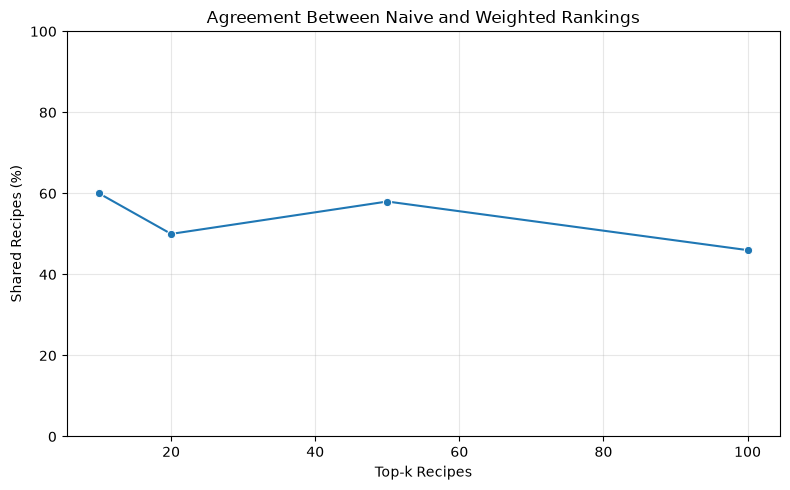

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.lineplot(
    data=top_k_comparisons,
    x="top_k",
    y="overlap_percentage",
    marker="o",
)

plt.title("Agreement Between Naive and Weighted Rankings")
plt.xlabel("Top-k Recipes")
plt.ylabel("Shared Recipes (%)")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Plot 2
Smoothing sensitivity

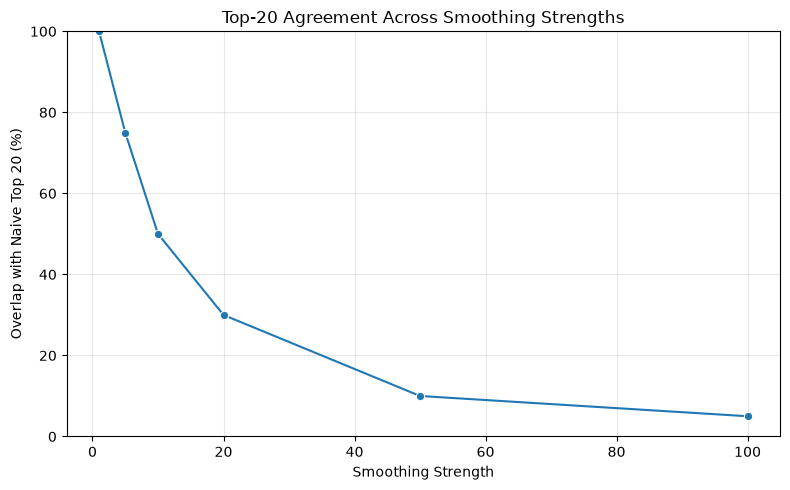

In [5]:
plt.figure(figsize=(8, 5))

sns.lineplot(
    data=smoothing_sensitivity,
    x="smoothing_strength",
    y="overlap_with_naive_percentage",
    marker="o",
)

plt.title("Top-20 Agreement Across Smoothing Strengths")
plt.xlabel("Smoothing Strength")
plt.ylabel("Overlap with Naive Top 20 (%)")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Plot 3
Rating-count distributions in the top 100

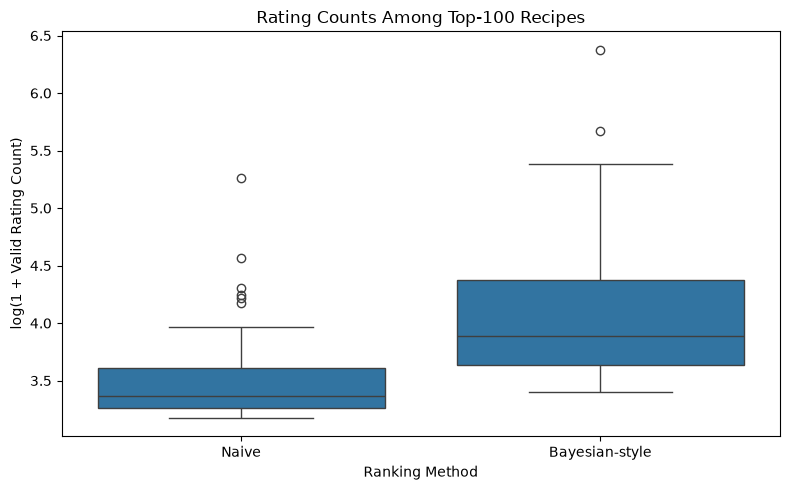

In [6]:
top_100_rating_counts = pd.concat(
    [
        naive_ranking.head(100)[["valid_rating_count"]].assign(
            ranking_method="Naive"
        ),
        bayesian_ranking.head(100)[["valid_rating_count"]].assign(
            ranking_method="Bayesian-style"
        ),
    ],
    ignore_index=True,
)

top_100_rating_counts["log_rating_count"] = (
    np.log1p(top_100_rating_counts["valid_rating_count"])
)

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=top_100_rating_counts,
    x="ranking_method",
    y="log_rating_count",
)

plt.title("Rating Counts Among Top-100 Recipes")
plt.xlabel("Ranking Method")
plt.ylabel("log(1 + Valid Rating Count)")
plt.tight_layout()
plt.show()
